# Figure 4

Parity plots

Repository root: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload
Results root: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/results
Figure directory: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/figures

Fe (Fe_d6)
  Predictions: 486
  File: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/results/Fe_d6/predictions.csv

Co (Co_d7)
  Predictions: 486
  File: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/results/Co_d

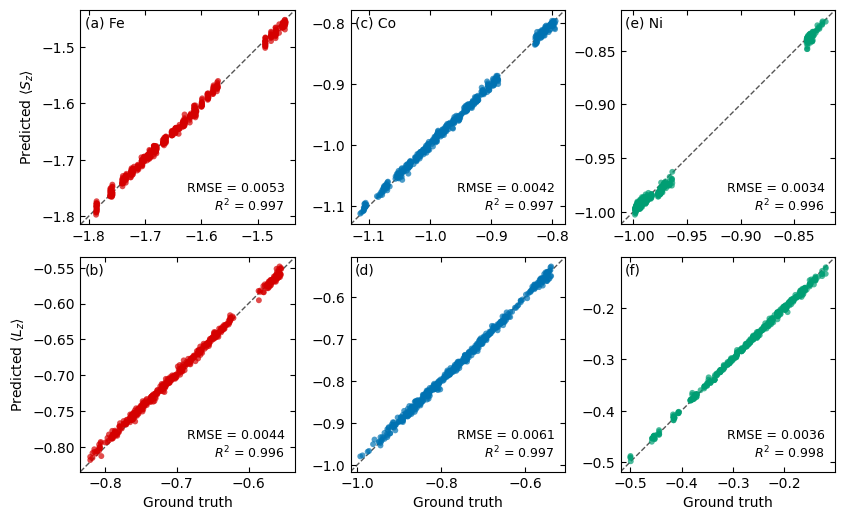


Figure 4 metric summary

Fe
  Sz: N=486, RMSE=5.25635663e-03, R2=0.9966329298273099
  Lz: N=486, RMSE=4.42671097e-03, R2=0.9961717261666354

Co
  Sz: N=486, RMSE=4.15407672e-03, R2=0.9974495867124167
  Lz: N=486, RMSE=6.09693462e-03, R2=0.9969736913700041

Ni
  Sz: N=486, RMSE=3.42639348e-03, R2=0.9963032744023448
  Lz: N=486, RMSE=3.61151109e-03, R2=0.9981590937027787

PNG saved to: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/figures/Figure4_multi_parity.png
PDF saved to: /Users/tetsuro/Library/CloudStorage/OneDrive-qst.go.jp/プロジェクト/3_メインプロジェクト/PRJ-M-017_R6安全保障技術研究推進制度/機械学習による解析法の開発/python_XMCD_analysis/261014_for_github_upload/figures/Figure4_multi_parity.pdf


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# Settings
# ============================================================

figure_name = "Figure4_multi_parity"

systems = {
    "Fe": "Fe_d6",
    "Co": "Co_d7",
    "Ni": "Ni_d8",
}

elements = list(
    systems.keys()
)

colors = {
    "Fe": "#D50000",
    "Co": "#0072B2",
    "Ni": "#009E73",
}

target_settings = {
    "Sz": {
        "row": 0,
        "column_prefix": "sz",
        "ylabel": r"Predicted $\langle S_z \rangle$",
    },

    "Lz": {
        "row": 1,
        "column_prefix": "lz",
        "ylabel": r"Predicted $\langle L_z \rangle$",
    },
}

panel_labels = {
    (0, 0): "(a)",
    (1, 0): "(b)",
    (0, 1): "(c)",
    (1, 1): "(d)",
    (0, 2): "(e)",
    (1, 2): "(f)",
}

marker_size = 18
marker_alpha = 0.70
output_dpi = 300

# Fractional padding applied to parity-plot limits.
axis_padding_fraction = 0.05


# ============================================================
# Repository-root detection
# ============================================================

def find_repository_root(
    start_directory=None,
):
    """
    Find the repository root by searching upward.

    The repository root must contain both:

        src/
        configs/
    """

    if start_directory is None:
        current_directory = Path.cwd().resolve()

    else:
        current_directory = (
            Path(
                start_directory
            )
            .expanduser()
            .resolve()
        )

    candidates = [
        current_directory,
        *current_directory.parents,
    ]

    for candidate in candidates:
        if (
            (
                candidate
                / "src"
            ).is_dir()
            and (
                candidate
                / "configs"
            ).is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Repository root could not be found. "
        "Expected directories 'src' and 'configs'."
    )


repository_root = find_repository_root()

results_root = (
    repository_root
    / "results"
)

output_directory = (
    repository_root
    / "figures"
)

output_directory.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "Repository root:",
    repository_root,
)

print(
    "Results root:",
    results_root,
)

print(
    "Figure directory:",
    output_directory,
)


# ============================================================
# JSON loader
# ============================================================

def load_json(
    path,
):
    """
    Load a UTF-8 JSON file.
    """

    path = Path(
        path
    )

    if not path.is_file():
        raise FileNotFoundError(
            f"JSON file was not found: {path}"
        )

    with path.open(
        "r",
        encoding="utf-8",
    ) as handle:
        return json.load(
            handle
        )


# ============================================================
# Metric calculations
# ============================================================

def calculate_metrics(
    y_true,
    y_pred,
):
    """
    Calculate regression metrics directly from plotted values.

    Definitions
    -----------
    residual = y_pred - y_true
    SSE      = sum(residual**2)
    SST      = sum((y_true - mean(y_true))**2)
    MSE      = SSE / N
    RMSE     = sqrt(MSE)
    R2       = 1 - SSE / SST

    Returns
    -------
    dict
        count, sse, sst, mse, rmse, and r2.
    """

    y_true = np.asarray(
        y_true,
        dtype=np.float64,
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64,
    )

    if y_true.ndim != 1:
        raise ValueError(
            "y_true must be one-dimensional"
        )

    if y_pred.ndim != 1:
        raise ValueError(
            "y_pred must be one-dimensional"
        )

    if y_true.shape != y_pred.shape:
        raise ValueError(
            "y_true and y_pred must have "
            "identical shapes"
        )

    if y_true.size == 0:
        raise ValueError(
            "Cannot calculate metrics from "
            "empty arrays"
        )

    if not np.isfinite(
        y_true
    ).all():
        raise ValueError(
            "y_true contains NaN or Inf"
        )

    if not np.isfinite(
        y_pred
    ).all():
        raise ValueError(
            "y_pred contains NaN or Inf"
        )

    residual = (
        y_pred
        - y_true
    )

    sse = float(
        np.sum(
            residual ** 2
        )
    )

    true_mean = float(
        np.mean(
            y_true
        )
    )

    sst = float(
        np.sum(
            (
                y_true
                - true_mean
            ) ** 2
        )
    )

    mse = float(
        sse
        / y_true.size
    )

    rmse = float(
        np.sqrt(
            mse
        )
    )

    if sst > 0.0:
        r2 = float(
            1.0
            - sse
            / sst
        )

    else:
        r2 = None

    return {
        "count": int(
            y_true.size
        ),

        "sse": (
            sse
        ),

        "sst": (
            sst
        ),

        "mse": (
            mse
        ),

        "rmse": (
            rmse
        ),

        "r2": (
            r2
        ),
    }


# ============================================================
# Axis-limit calculation
# ============================================================

def calculate_parity_limits(
    y_true,
    y_pred,
    padding_fraction=0.05,
):
    """
    Calculate common square-axis limits for a parity plot.

    The limits encompass both ground-truth and predicted values
    and include a fractional margin on each side.
    """

    y_true = np.asarray(
        y_true,
        dtype=np.float64,
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64,
    )

    combined = np.concatenate(
        [
            y_true,
            y_pred,
        ]
    )

    data_min = float(
        np.min(
            combined
        )
    )

    data_max = float(
        np.max(
            combined
        )
    )

    data_range = (
        data_max
        - data_min
    )

    if data_range > 0.0:
        margin = (
            padding_fraction
            * data_range
        )

    else:
        # Safeguard for a constant target.
        margin = max(
            1.0e-6,
            abs(
                data_min
            )
            * padding_fraction,
        )

    return (
        data_min
        - margin,
        data_max
        + margin,
    )


# ============================================================
# Load predictions and published metrics
# ============================================================

results = {}

for element, system_name in systems.items():
    result_directory = (
        results_root
        / system_name
    )

    predictions_file = (
        result_directory
        / "predictions.csv"
    )

    metrics_file = (
        result_directory
        / "metrics.json"
    )

    if not predictions_file.is_file():
        raise FileNotFoundError(
            "Predictions file was not found:\n"
            f"{predictions_file}\n"
            "Run evaluate.py before generating Figure 4."
        )

    if not metrics_file.is_file():
        raise FileNotFoundError(
            "Metrics file was not found:\n"
            f"{metrics_file}\n"
            "Run evaluate.py before generating Figure 4."
        )

    predictions = pd.read_csv(
        predictions_file
    )

    metrics = load_json(
        metrics_file
    )

    required_columns = {
        "sample_id",
        "sz_true",
        "sz_pred",
        "lz_true",
        "lz_pred",
    }

    missing_columns = (
        required_columns
        - set(
            predictions.columns
        )
    )

    if missing_columns:
        raise ValueError(
            f"{predictions_file.name} is missing "
            "required columns: "
            f"{sorted(missing_columns)}"
        )

    if predictions.empty:
        raise ValueError(
            f"{predictions_file.name} contains no rows"
        )

    if predictions[
        "sample_id"
    ].duplicated().any():
        raise ValueError(
            f"{predictions_file.name} contains "
            "duplicate sample_id values"
        )

    numeric_columns = [
        "sz_true",
        "sz_pred",
        "lz_true",
        "lz_pred",
    ]

    for column in numeric_columns:
        values = predictions[
            column
        ].to_numpy(
            dtype=np.float64
        )

        if not np.isfinite(
            values
        ).all():
            raise ValueError(
                f"{predictions_file.name}: "
                f"{column} contains NaN or Inf"
            )

    expected_count = metrics.get(
        "prediction_count"
    )

    if (
        expected_count is not None
        and int(
            expected_count
        ) != len(
            predictions
        )
    ):
        raise ValueError(
            f"{system_name}: predictions.csv contains "
            f"{len(predictions)} rows, but metrics.json "
            f"reports {expected_count} predictions."
        )

    results[
        element
    ] = {
        "system_name": (
            system_name
        ),

        "predictions": (
            predictions
        ),

        "metrics": (
            metrics
        ),

        "predictions_file": (
            predictions_file
        ),

        "metrics_file": (
            metrics_file
        ),
    }

    print()
    print(
        f"{element} ({system_name})"
    )

    print(
        "  Predictions:",
        len(
            predictions
        ),
    )

    print(
        "  File:",
        predictions_file,
    )


# ============================================================
# Verify plotted metrics against metrics.json
# ============================================================

metric_report = {}

for element in elements:
    predictions = results[
        element
    ][
        "predictions"
    ]

    saved_metrics = results[
        element
    ][
        "metrics"
    ]

    physical_metrics = saved_metrics.get(
        "physical_target_space",
        {},
    )

    saved_per_target = physical_metrics.get(
        "per_target",
        {},
    )

    metric_report[
        element
    ] = {}

    for target_name, settings in (
        target_settings.items()
    ):
        prefix = settings[
            "column_prefix"
        ]

        y_true = predictions[
            f"{prefix}_true"
        ].to_numpy(
            dtype=np.float64
        )

        y_pred = predictions[
            f"{prefix}_pred"
        ].to_numpy(
            dtype=np.float64
        )

        calculated = calculate_metrics(
            y_true,
            y_pred,
        )

        saved_target_metrics = (
            saved_per_target.get(
                target_name
            )
        )

        if saved_target_metrics is not None:
            saved_rmse = saved_target_metrics.get(
                "rmse"
            )

            saved_r2 = saved_target_metrics.get(
                "r2_coefficient_of_determination"
            )

            if (
                saved_rmse is not None
                and not np.isclose(
                    calculated[
                        "rmse"
                    ],
                    float(
                        saved_rmse
                    ),
                    rtol=1.0e-10,
                    atol=1.0e-12,
                )
            ):
                raise ValueError(
                    f"{element} {target_name}: "
                    "RMSE calculated from predictions.csv "
                    "does not match metrics.json."
                )

            calculated_r2 = calculated[
                "r2"
            ]

            if (
                calculated_r2 is not None
                and saved_r2 is not None
                and not np.isclose(
                    calculated_r2,
                    float(
                        saved_r2
                    ),
                    rtol=1.0e-10,
                    atol=1.0e-12,
                )
            ):
                raise ValueError(
                    f"{element} {target_name}: "
                    "R2 calculated from predictions.csv "
                    "does not match metrics.json."
                )

        metric_report[
            element
        ][
            target_name
        ] = calculated


# ============================================================
# Figure
# ============================================================

figure, axes = plt.subplots(
    2,
    3,
    figsize=(
        10.0,
        6.0,
    ),
)

figure.subplots_adjust(
    wspace=0.15,
    hspace=0.15,
)


# ============================================================
# Draw parity plots
# ============================================================

for column, element in enumerate(
    elements
):
    predictions = results[
        element
    ][
        "predictions"
    ]

    color = colors[
        element
    ]

    for target_name, settings in (
        target_settings.items()
    ):
        row = settings[
            "row"
        ]

        prefix = settings[
            "column_prefix"
        ]

        axis = axes[
            row,
            column,
        ]

        y_true = predictions[
            f"{prefix}_true"
        ].to_numpy(
            dtype=np.float64
        )

        y_pred = predictions[
            f"{prefix}_pred"
        ].to_numpy(
            dtype=np.float64
        )

        lower_limit, upper_limit = (
            calculate_parity_limits(
                y_true,
                y_pred,
                padding_fraction=(
                    axis_padding_fraction
                ),
            )
        )

        # ----------------------------------------------------
        # Data points
        # ----------------------------------------------------

        axis.scatter(
            y_true,
            y_pred,
            s=marker_size,
            alpha=marker_alpha,
            color=color,
            edgecolors="none",
            rasterized=True,
            zorder=2,
        )

        # ----------------------------------------------------
        # Ideal y = x line
        # ----------------------------------------------------

        axis.plot(
            [
                lower_limit,
                upper_limit,
            ],
            [
                lower_limit,
                upper_limit,
            ],
            linestyle="--",
            color="#555555",
            linewidth=1.0,
            zorder=1,
        )

        axis.set_xlim(
            lower_limit,
            upper_limit,
        )

        axis.set_ylim(
            lower_limit,
            upper_limit,
        )

        axis.set_aspect(
            "equal",
            adjustable="box",
        )

        axis.tick_params(
            direction="in",
            which="both",
            top=True,
            right=True,
        )

        # ----------------------------------------------------
        # Panel label
        # ----------------------------------------------------

        panel_text = panel_labels[
            (
                row,
                column,
            )
        ]

        if row == 0:
            panel_text = (
                f"{panel_text} {element}"
            )

        axis.text(
            0.02,
            0.97,
            panel_text,
            transform=axis.transAxes,
            horizontalalignment="left",
            verticalalignment="top",
        )

        # ----------------------------------------------------
        # Metrics annotation
        # ----------------------------------------------------

        target_metrics = metric_report[
            element
        ][
            target_name
        ]

        rmse = target_metrics[
            "rmse"
        ]

        r2 = target_metrics[
            "r2"
        ]

        if r2 is None:
            metric_text = (
                f"RMSE = {rmse:.4f}\n"
                r"$R^2$ = undefined"
            )

        else:
            metric_text = (
                f"RMSE = {rmse:.4f}\n"
                rf"$R^2$ = {r2:.3f}"
            )

        axis.text(
            0.95,
            0.05,
            metric_text,
            transform=axis.transAxes,
            horizontalalignment="right",
            verticalalignment="bottom",
            fontsize=9,
        )


# ============================================================
# Axis labels
# ============================================================

axes[
    0,
    0,
].set_ylabel(
    r"Predicted $\langle S_z \rangle$"
)

axes[
    1,
    0,
].set_ylabel(
    r"Predicted $\langle L_z \rangle$"
)

for column in range(
    3
):
    axes[
        1,
        column,
    ].set_xlabel(
        "Ground truth"
    )


# ============================================================
# Save
# ============================================================

png_file = (
    output_directory
    / f"{figure_name}.png"
)

pdf_file = (
    output_directory
    / f"{figure_name}.pdf"
)

figure.savefig(
    png_file,
    dpi=output_dpi,
    bbox_inches="tight",
)

figure.savefig(
    pdf_file,
    bbox_inches="tight",
)

plt.show()

plt.close(
    figure
)


# ============================================================
# Final report
# ============================================================

print()
print(
    "Figure 4 metric summary"
)

print(
    "=" * 70
)

for element in elements:
    print()
    print(
        element
    )

    for target_name in (
        "Sz",
        "Lz",
    ):
        values = metric_report[
            element
        ][
            target_name
        ]

        print(
            f"  {target_name}: "
            f"N={values['count']}, "
            f"RMSE={values['rmse']:.8e}, "
            f"R2={values['r2']}"
        )

print()
print(
    "PNG saved to:",
    png_file,
)

print(
    "PDF saved to:",
    pdf_file,
)